# 01 楠梓外氣品質分析（Air Quality，Nanzih）

**核心對象**：一張楠梓測站的逐時長表，每一列是「某測站、某測項、某個整點」的一筆量測，欄位為 `datetime、site、item、value、flag`。本 notebook 把環境部原始的「一天一列、24 個小時欄」寬表攤平成這張長表，之後所有統計都從它出發。

**輸入**：環境部國家空品測站 2021～2025 年「全年逐時資料」（高屏空品區年度檔，已解壓到 `data/raw/airtw/<年份>/<站名>_<年份>.csv`）。

- 資料來源 : https://airtw.moenv.gov.tw/CHT/Query/His_Data.aspx

**輸出**：

- `data/processed/01_design_inputs_Nanzih.csv`：**設計主要資料**，長格式（category、item、metric、value、unit、note），內容有三類：
  - **PM**：PM2.5、PM10 五年小時值的平均、P50、P95、P99、最大值並列，作為 MAU 濾網負荷（Cout）的候選值；設計值取哪一個統計量由設計組決定。
  - **AMC**（空氣分子污染物）：SO2、NO2、O3 的平均、P95、P99，另以 µg/m³ 和 ISO 14644-8 等級表示，作為化學濾網選型的依據；NMHC 保留原單位，NH3、H2S 測站沒有資料。
  - **WIND**：盛行風向、靜風比例、海風方位頻率，以及各污染物濃度最高的來向，供判斷 MAU 進氣口方位與是否需要鹽霧濾網。
- `data/processed/01_aq_annual_stats_Nanzih.csv`：各測項逐年的平均、中位、P95、P99、最大值與有效率。
- `data/processed/01_aq_profiles_Nanzih.csv`：月剖面與日剖面（kind、site、item、bin、value），給安排季節性或分時段控制用。
- `data/processed/01_aq_hourly_long.csv`：五年逐時長表，供其他分析重用。
- 圖 `report/figures/01_*.png`：PM 日平均時間序列、月剖面、日剖面、風玫瑰、污染玫瑰。

ISO 16890 濾網等級的換算只在第 6.2 節顯示，不出檔，因為目標濃度尚未決定，表中數字只是示例。

**內容說明**：第 1 節是全部設定，換站、換年、改門檻只改那一個 cell；第 2 節做出依據原始資料做前處理；第 3～5 節每個函式讀取經處理後的資訊，並依據所需特定內容回傳一張小表；第 6 節把小表翻成設計輸入；第 7 節印出摘要。細節部分可看章節說明「為什麼這樣做」。

## 1. 設定

In [ ]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 路徑：notebook 在 notebooks/ 下執行時，專案根目錄是上一層
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT / "data" / "raw" / "airtw"
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "report" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
PREFIX = "01"                      # 輸出檔名前綴，避免與其他 notebook 的輸出混在一起

# ---- 測站與年份
SITE = "楠梓"                      # 主站
COMPARE_SITES = []                 # 對照站，例如 ["橋頭", "仁武", "左營"]；留空只跑主站
SITES = [SITE] + COMPARE_SITES
YEARS = list(range(2021, 2026))

# 測站基本資料（來源：環境部 API aqx_p_07，座標 TWD97）；en 欄給輸出檔名用，輸出檔名一律英文
STATION_META = pd.DataFrame(
    [["楠梓", "Nanzih", 53, "一般站", 120.328289, 22.733667, "高雄市楠梓區楠梓路262號"],
     ["橋頭", "Qiaotou", 48, "背景站", 120.305689, 22.757506, "高雄市橋頭區隆豐北路1號"],
     ["仁武", "Renwu", 49, "一般站", 120.332631, 22.689056, "高雄市仁武區八卦里永仁街555號"],
     ["左營", "Zuoying", 54, "一般站", 120.292917, 22.674861, "高雄市左營區翠華路687號"]],
    columns=["site", "en", "siteid", "sitetype", "lon", "lat", "address"]).set_index("site")
SITE_EN = STATION_META.loc[SITE, "en"]

# ---- 測項（名稱沿用原始檔）
ITEMS_PM = ["PM2.5", "PM10"]
ITEMS_GAS = ["SO2", "NO2", "NOx", "O3", "NMHC", "CO"]
ITEM_WD, ITEM_WS = "WIND_DIREC", "WIND_SPEED"   # 原始檔另有 WD_HR／WS_HR（小時平均向量），本分析用瞬時小時值
ITEMS_USED = ITEMS_PM + ITEMS_GAS + [ITEM_WD, ITEM_WS]
UNITS = {"PM2.5": "µg/m³", "PM10": "µg/m³", "SO2": "ppb", "NO2": "ppb", "NOx": "ppb", "O3": "ppb",
         "NMHC": "ppmC", "CO": "ppm", "WIND_DIREC": "deg", "WIND_SPEED": "m/s"}

# ---- 原始檔的無效值標記（整格換成標記，非數值後綴）
FLAGS = {"#": "儀器檢核無效或超出偵測極限", "*": "程式檢核無效", "x": "人工檢核無效",
         "A": "儀器檢核", "NA": "缺值"}

# ---- 統計參數
REF_PCT = 95           # 示例換算用的參考百分位；設計值要取平均、P95 還是 P99 由設計組決定，表中幾個統計量都會並列
COVERAGE_MIN = 0.75    # 某測項某年有效率低於此值時，在表中標示「有效率不足」，使用本筆測站要考量數據不足的問題
CALM_WS = 0.5          # 靜風門檻（m/s），低於此值不計入風向頻率
DAILY_MIN_HOURS = 16   # 日平均至少要有的有效小時數（依據環境部慣例 16／24）

# ---- 日平均圖的參考線（台灣空氣品質標準日均值，µg/m³）；只當讀圖尺度，不做超標判定
PM_REF_LINE = {"PM2.5": 35, "PM10": 100}
MW = {"SO2": 64.07, "NO2": 46.01, "O3": 48.00}   # g/mol，ppb → µg/m³ 用

# ---- 繪圖設定：中文字型（Windows 內建微軟正黑體）
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

## 2. 載入與資料前處理

原始 CSV 一列是「某站、某日、某測項」加 24 個小時欄，無效值不是數字後面加記號，而是整格換成 `#`、`*`、`x`、`A`、`NA`。載入做兩件事：

- **攤開成長表**：後面所有統計都是「依測項、依時間分組」，長表一個 `groupby` 就能做；寬表每多一個測項就要多一欄處理。需要跨測項對照（例如 PM2.5 對風向）時再臨時 `pivot`。
  
- **把標記拆成 `value` 與 `flag` 兩欄**：`value` 是數值（無效為 NaN），`flag` 保留原始標記。保留 flag 的原因是無效小時的比例本身是資訊，某測項某年有效率太低時統計就不能用，丟掉標記就查不回來。

**示意**：以楠梓站 2021-01-07 的 PM2.5 為例。原始寬表是一列加 24 個小時欄，11 時那格是無效標記 `#`：

| 測站 | 日期 | 測項 | 00 | 01 | … | 10 | 11 | 12 | … | 23 |
|---|---|---|---|---|---|---|---|---|---|---|
| 楠梓 | 2021/01/07 00:00:00 | PM2.5 | 30 | 35 | … | 17 | # | 22 | … | 12 |

攤開後這一列變成 24 列，每列只放一個量測值，原本藏在欄名裡的小時併進 `datetime` 欄；`#` 拆成 `value` 為 NaN、`flag` 為 `#`：

| datetime | site | item | value | flag |
|---|---|---|---|---|
| 2021-01-07 00:00 | 楠梓 | PM2.5 | 30.0 | |
| 2021-01-07 01:00 | 楠梓 | PM2.5 | 35.0 | |
| … | … | … | … | … |
| 2021-01-07 10:00 | 楠梓 | PM2.5 | 17.0 | |
| 2021-01-07 11:00 | 楠梓 | PM2.5 | NaN | # |
| 2021-01-07 12:00 | 楠梓 | PM2.5 | 22.0 | |
| … | … | … | … | … |
| 2021-01-07 23:00 | 楠梓 | PM2.5 | 12.0 | |

長表存成 CSV：五年 × 18 測項 × 8,760 小時約 79 萬列，CSV 約 30 MB，讀取不存在問題，不使用 pkl 等資料格式。

輸出 : 

* **有效率表**：最後一張表格，目的是在進入統計之前，先確認每個測項每年的資料夠不夠完整。年平均與 P95 只由有效小時算出，缺漏越多，代表性越差；若缺漏又集中在某個季節（例如冬季 PM 高峰期儀器故障），算出的 P95 會系統性偏低，拿去當設計用 Cout 就會低估濾網負荷。判讀方式是看有沒有任何一格低於 `COVERAGE_MIN`：有的話，第 3 節年統計表的 `low_coverage` 欄會標為 True，第 7 節摘要也會列出該測項與年份，報告引用那一年的數字時要註明。




In [68]:
def load_site_year(site: str, year: int) -> pd.DataFrame:
    '''讀一站一年的原始 CSV，回傳長表（datetime, site, item, value, flag）。'''
    path = RAW_DIR / str(year) / f"{site}_{year}.csv"
    raw = pd.read_csv(path, encoding="utf-8-sig", dtype=str)
    raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]          # 每列結尾多一個空欄
    raw = raw.rename(columns={"測站": "site", "日期": "date", "測項": "item"})
    hour_cols = [f"{h:02d}" for h in range(24)]
    long = raw.melt(id_vars=["site", "date", "item"], value_vars=hour_cols,
                    var_name="hour", value_name="raw")
    long["datetime"] = (pd.to_datetime(long["date"].str[:10], format="%Y/%m/%d")
                        + pd.to_timedelta(long["hour"].astype(int), unit="h"))
    long["raw"] = long["raw"].str.strip().fillna("NA")
    long["value"] = pd.to_numeric(long["raw"], errors="coerce")
    # 帶標記的格一律視為無效；flag 只留非數字部分（原始檔偶有「數字＋A」的寫法，例如 39A，也歸為 A）
    marker = long["raw"].str.replace(r"[-\d.]", "", regex=True).replace("", "NA")
    long["flag"] = np.where(long["value"].isna(), marker, "")
    return (long[["datetime", "site", "item", "value", "flag"]]
            .sort_values(["site", "item", "datetime"]).reset_index(drop=True))


def load_all(sites, years) -> pd.DataFrame:
    frames = [load_site_year(s, y) for s in sites for y in years]
    return pd.concat(frames, ignore_index=True)


def coverage(df: pd.DataFrame) -> pd.DataFrame:
    '''測項 × 年的有效小時比例（0～1）。'''
    t = df.assign(year=df["datetime"].dt.year, valid=df["value"].notna())
    return t.groupby(["site", "item", "year"])["valid"].mean().unstack("year").round(3)


def flag_summary(df: pd.DataFrame) -> pd.DataFrame:
    '''各標記出現次數，確認原始檔的標記種類沒有超出 FLAGS 的定義。'''
    t = df.loc[df["flag"] != "", "flag"].value_counts().rename("count").to_frame()
    t["meaning"] = [FLAGS.get(k, "未定義的標記，請檢查") for k in t.index]
    return t


hourly = load_all(SITES, YEARS)
hourly.to_csv(PROC_DIR / f"{PREFIX}_aq_hourly_long.csv", index=False)
print("長表列數:", len(hourly), "| 期間:", hourly["datetime"].min(), "→", hourly["datetime"].max())

cov = coverage(hourly)          # 有效率只在 notebook 內顯示，並併入第 3 節年統計表的 coverage 欄，不另外出檔
display(flag_summary(hourly))
display(cov.loc[(slice(None), ITEMS_USED), :])

長表列數: 788832 | 期間: 2021-01-01 00:00:00 → 2025-12-31 23:00:00


,count,meaning
flag,,
#,6146,儀器檢核無效或超出偵測極限
NA,2882,缺值
x,1034,人工檢核無效
*,445,程式檢核無效
A,205,儀器檢核


year              2021   2022   2023   2024   2025
site item                                         
楠梓   PM2.5       0.952  0.992  0.993  0.992  0.991
     PM10        0.951  0.991  0.992  0.991  0.965
     SO2         0.961  0.984  0.990  0.980  0.985
     NO2         0.957  0.986  0.988  0.985  0.987
     NOx         0.957  0.986  0.988  0.985  0.987
     O3          0.964  0.984  0.988  0.987  0.989
     NMHC        0.972  0.992  0.991  0.988  0.973
     CO          0.975  0.991  0.991  0.989  0.992
     WIND_DIREC  0.982  0.999  0.999  0.997  0.999
     WIND_SPEED  0.982  0.999  0.999  0.997  0.999

## 3. 基本統計

**年統計**：每測項每年的平均、中位、P95、P99、最大值，全部是小時值的統計（每年約 8,760 筆有效小時）。設計用濃度通取高百分位，因為濾網與化學濾網要撐過高濃度時段；也不取最大值，因為最大值常是沙塵或單一事件。P95 代表一年約 438 小時(5%)會超過的水準。有效率低於 `COVERAGE_MIN` 的年份會在 `low_coverage` 欄標示。

**日平均時間序列圖**：畫開心的，把 PM2.5、PM10 的小時值做成日平均（至少 `DAILY_MIN_HOURS` 個有效小時才算一天）畫成五年的時間序列，用來看高濃度集中在哪些季節、年際之間有沒有趨勢；圖上的虛線是台灣空品標準的日均值，只當參考線，不據此做超標判定。

mean  median    p95      p99     max  n_valid  coverage  \
item  year                                                              
CO    2021   0.326    0.31   0.59    0.776    1.40     8537     0.975   
      2022   0.308    0.30   0.53    0.660    1.02     8679     0.991   
      2023   0.303    0.29   0.52    0.672    1.02     8685     0.991   
      2024   0.298    0.29   0.52    0.630    1.32     8686     0.989   
      2025   0.266    0.26   0.46    0.590    0.97     8686     0.992   
NMHC  2021   0.138    0.11   0.36    0.690    2.74     8517     0.972   
      2022   0.090    0.07   0.24    0.440    2.10     8688     0.992   
      2023   0.078    0.06   0.23    0.420    1.68     8681     0.991   
      2024   0.083    0.06   0.24    0.463    3.38     8675     0.988   
      2025   0.092    0.07   0.24    0.470    5.05     8524     0.973   
NO2   2021  14.094   13.10  27.90   36.700   59.50     8387     0.957   
      2022  13.437   12.80  24.60   32.400   54.10     8635     0.986   
      2023  12.966   12.00  24.20   33.000   62.20     8651     0.988   
      2024  12.570   11.90  23.35   30.800   45.10     8651     0.985   
      2025  11.820   10.90  22.50   31.058   56.10     8643     0.987   
NOx   2021  17.286   15.60  34.70   53.428  125.30     8387     0.957   
      2022  15.897   14.60  31.10   43.700   86.20     8635     0.986   
      2023  15.025   13.40  29.60   43.450   94.70     8651     0.988   
      2024  14.627   13.40  28.75   40.250  127.00     8651     0.985   
      2025  13.849   12.20  28.00   41.774   89.10     8643     0.987   
O3    2021  27.479   22.40  67.50   80.052  104.70     8449     0.964   
      2022  27.068   21.60  67.70   81.800  114.60     8624     0.984   
      2023  28.995   23.80  67.00   79.786  117.50     8658     0.988   
      2024  28.138   23.70  65.40   79.331  124.00     8670     0.987   
      2025  27.770   23.80  63.30   76.100   95.40     8664     0.989   
PM10  2021  41.560   36.00  90.00  115.000  242.00     8333     0.951   
      2022  35.905   33.00  73.00   91.000  136.00     8681     0.991   
      2023  40.707   38.00  83.00  108.000  222.00     8686     0.992   
      2024  39.396   36.00  78.00   99.000  188.00     8704     0.991   
      2025  40.510   36.00  83.00  113.000  175.00     8454     0.965   
PM2.5 2021  20.579   18.00  49.00   65.000  143.00     8339     0.952   
      2022  17.333   15.00  39.00   52.000   84.00     8688     0.992   
      2023  17.682   15.00  40.00   52.000   84.00     8696     0.993   
      2024  17.737   16.00  39.00   50.910   75.00     8710     0.992   
      2025  17.277   15.00  37.00   52.000   76.00     8685     0.991   
SO2   2021   2.102    1.90   4.10    6.082   24.10     8419     0.961   
      2022   1.837    1.70   3.50    5.100   12.00     8617     0.984   
      2023   1.707    1.60   3.30    5.200   13.70     8673     0.990   
      2024   1.560    1.40   3.00    4.800   11.60     8608     0.980   
      2025   1.379    1.30   2.60    4.000    9.10     8627     0.985   

            low_coverage   unit  
item  year                       
CO    2021         False    ppm  
      2022         False    ppm  
      2023         False    ppm  
      2024         False    ppm  
      2025         False    ppm  
NMHC  2021         False   ppmC  
      2022         False   ppmC  
      2023         False   ppmC  
      2024         False   ppmC  
      2025         False   ppmC  
NO2   2021         False    ppb  
      2022         False    ppb  
      2023         False    ppb  
      2024         False    ppb  
      2025         False    ppb  
NOx   2021         False    ppb  
      2022         False    ppb  
      2023         False    ppb  
      2024         False    ppb  
      2025         False    ppb  
O3    2021         False    ppb  
      2022         False    ppb  
      2023         False    ppb  
      2024         False    ppb  
      2025         False    ppb  
PM10  2021         False  µg/

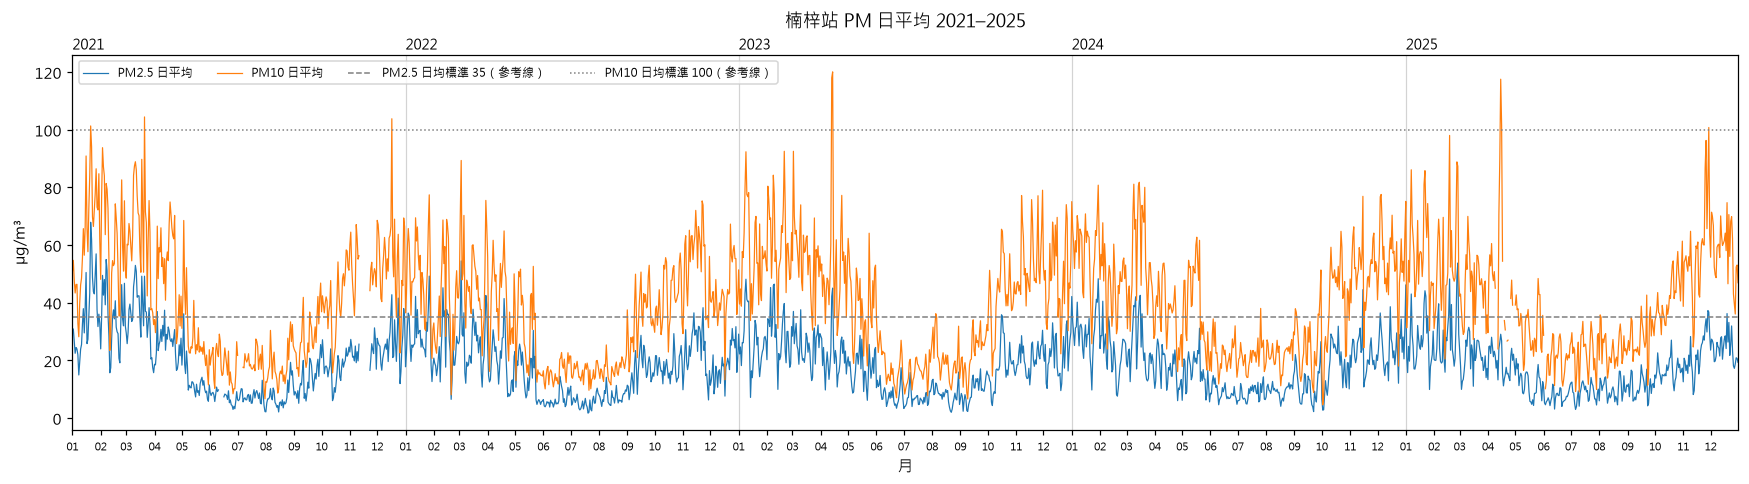

In [69]:
import matplotlib.dates as mdates


def _wide(df: pd.DataFrame, site: str, items) -> pd.DataFrame:
    '''單站、指定測項的寬表（index=datetime, columns=item）。'''
    t = df[(df["site"] == site) & (df["item"].isin(items))]
    return t.pivot(index="datetime", columns="item", values="value").sort_index()


def annual_stats(df: pd.DataFrame, items, cov: pd.DataFrame) -> pd.DataFrame:
    t = df[df["item"].isin(items)].assign(year=df["datetime"].dt.year)
    g = t.groupby(["site", "item", "year"])["value"]
    out = pd.DataFrame({
        "mean": g.mean(), "median": g.median(),
        "p95": g.quantile(0.95), "p99": g.quantile(0.99), "max": g.max(),
        "n_valid": g.count(),
    })
    cov_long = cov.stack().rename("coverage")
    cov_long.index.names = ["site", "item", "year"]
    out = out.join(cov_long)
    out["low_coverage"] = out["coverage"] < COVERAGE_MIN
    out["unit"] = [UNITS.get(i, "") for i in out.index.get_level_values("item")]
    return out.round(3)


def _daily_mean(w: pd.DataFrame) -> pd.DataFrame:
    d = w.resample("D").mean()
    n = w.resample("D").count()
    return d.where(n >= DAILY_MIN_HOURS)


stats = annual_stats(hourly, ITEMS_PM + ITEMS_GAS, cov)
stats.to_csv(PROC_DIR / f"{PREFIX}_aq_annual_stats_{SITE_EN}.csv")
display(stats.loc[SITE])

# 日平均時間序列圖（PM）：x 軸每月一個刻度，標籤為月份；每年 1 月加分隔線並在上方標年份
w_pm = _wide(hourly, SITE, ITEMS_PM)
d_pm = _daily_mean(w_pm)
fig, ax = plt.subplots(figsize=(16, 4.5))
for item in ITEMS_PM:
    ax.plot(d_pm.index, d_pm[item], lw=0.8, label=f"{item} 日平均")
for (item, ref), ls in zip(PM_REF_LINE.items(), ("--", ":")):
    ax.axhline(ref, ls=ls, lw=1, color="gray", label=f"{item} 日均標準 {ref}（參考線）")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.tick_params(axis="x", labelsize=7)
for y in YEARS:
    ax.axvline(pd.Timestamp(y, 1, 1), color="lightgray", lw=0.8, zorder=0)
    ax.text(pd.Timestamp(y, 1, 1), 1.01, str(y), transform=ax.get_xaxis_transform(),
            fontsize=9, ha="left", va="bottom")
ax.set_xlim(pd.Timestamp(YEARS[0], 1, 1), pd.Timestamp(YEARS[-1], 12, 31))
ax.set_xlabel("月"); ax.set_ylabel("µg/m³")
ax.set_title(f"{SITE}站 PM 日平均 {YEARS[0]}–{YEARS[-1]}", pad=18)
ax.legend(ncol=4, fontsize=8); fig.tight_layout()
fig.savefig(FIG_DIR / f"{PREFIX}_pm_daily_timeseries.png"); plt.show()

## 4. 月剖面與日剖面

採用類似於 Monte Carlo 的方式，把五年的小時值依「月」(3,300～3,650 筆)與「一天中的小時」(約 1,770～1,810 筆)分別取平均，。目的不是描述氣候，而是回答兩個設計問題：

- **季節**：高雄冬季受東北季風與境外傳輸影響 PM 偏高、夏季光化學反應強 O3 偏高。若高濃度集中在特定季節，MAU 的化學濾網更換週期與進氣控制可以按季節安排。
- **日夜**：若某污染物白天明顯高於夜間（例如 O3），或夜間逆溫使 PM 累積，進氣口位置與分時段控制就有依據。

月剖面每格 3,326～3,693 筆小時值；日剖面每格 1,703～1,818 筆小時值


month,1,2,3,4,5,6,7,8,9,10,11,12
item,,,,,,,,,,,,
NMHC,0.12,0.10,0.11,0.10,0.09,0.08,0.07,0.08,0.08,0.09,0.11,0.11
NO2,17.50,15.66,15.99,12.34,11.17,9.39,8.41,9.56,10.16,12.49,15.78,17.41
O3,27.99,29.76,32.21,34.71,29.84,18.58,20.18,20.47,28.23,34.46,31.91,26.75
PM10,56.81,52.62,53.94,46.09,33.45,19.07,18.94,20.31,27.83,41.16,54.47,51.99
PM2.5,29.41,27.73,26.63,20.85,14.58,7.72,7.42,8.50,12.26,17.41,22.29,22.99
SO2,1.87,1.78,1.90,1.81,1.81,1.60,1.72,1.41,1.49,1.59,1.82,1.79


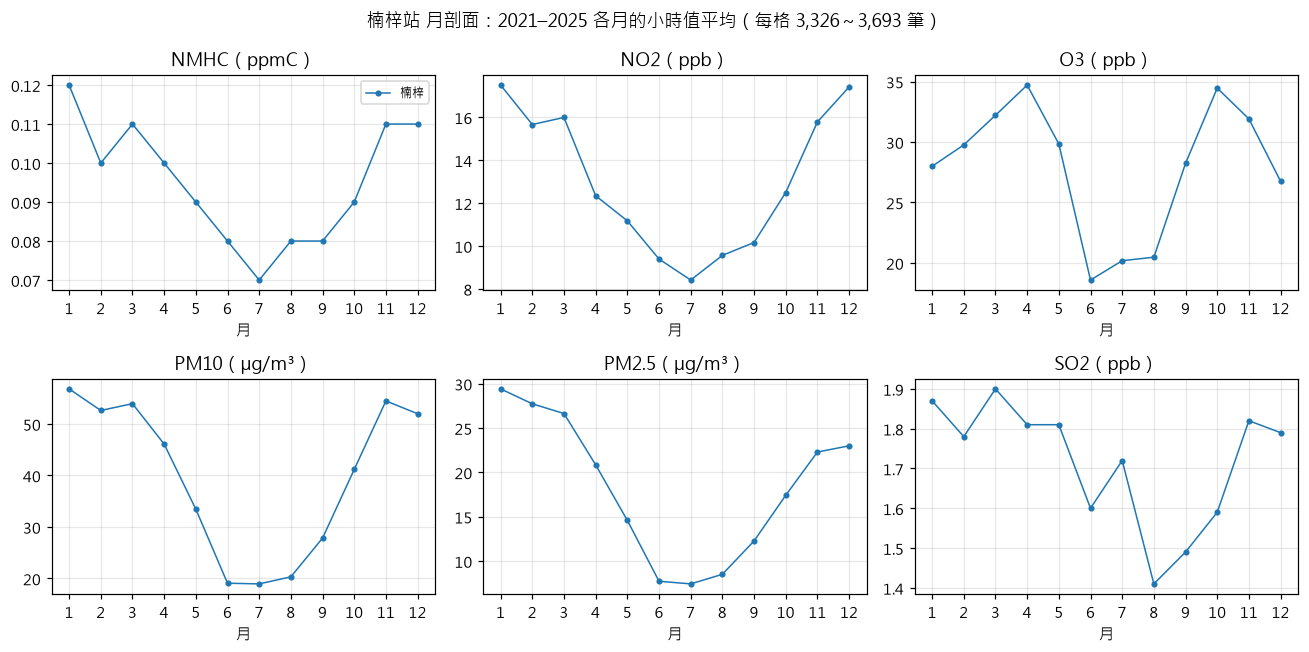

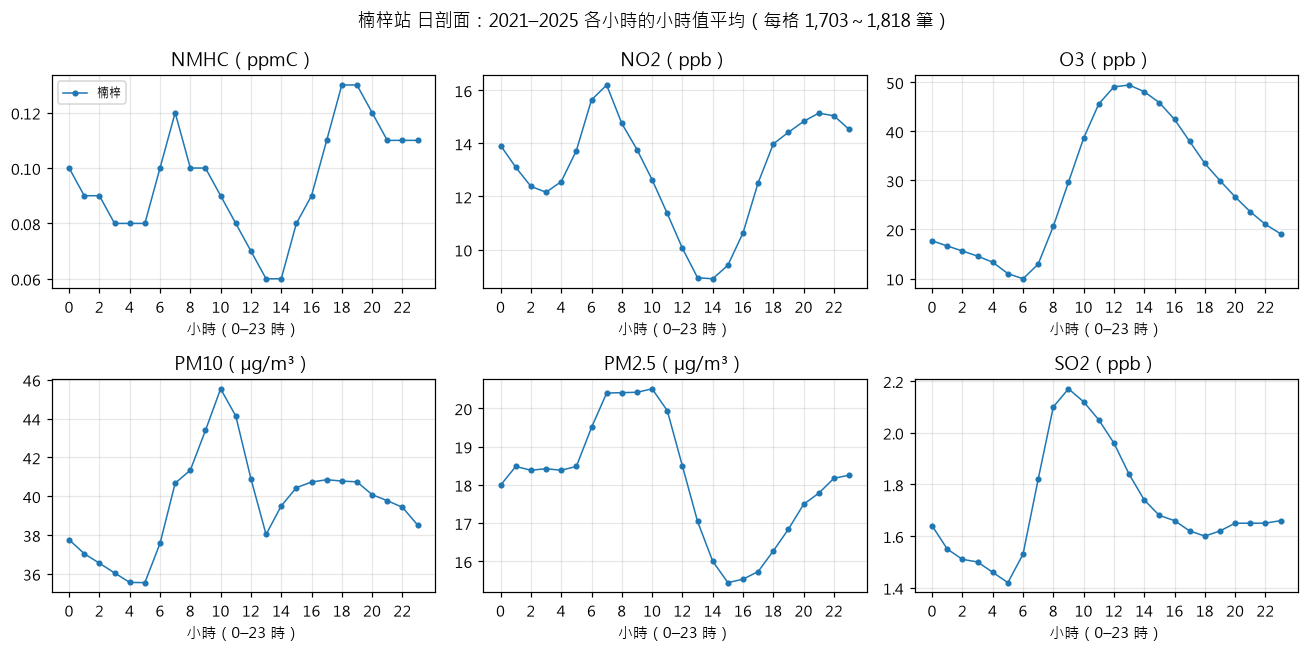

In [70]:
def monthly_profile(df: pd.DataFrame, items) -> pd.DataFrame:
    t = df[df["item"].isin(items)].assign(month=df["datetime"].dt.month)
    return t.groupby(["site", "item", "month"])["value"].mean().unstack("month").round(2)


def diurnal_profile(df: pd.DataFrame, items) -> pd.DataFrame:
    t = df[df["item"].isin(items)].assign(hour=df["datetime"].dt.hour)
    return t.groupby(["site", "item", "hour"])["value"].mean().unstack("hour").round(2)


def _bin_counts(df: pd.DataFrame, items, by: str) -> pd.Series:
    '''主站每個分組格子裡進入平均的有效小時值筆數（by = "month" 或 "hour"），用來標在圖的標題。'''
    t = df[(df["site"] == SITE) & df["item"].isin(items)]
    key = getattr(t["datetime"].dt, by)
    return t.groupby([t["item"], key])["value"].count()


ITEMS_PROFILE = ITEMS_PM + ["SO2", "NO2", "O3", "NMHC"]
mon = monthly_profile(hourly, ITEMS_PROFILE)
diu = diurnal_profile(hourly, ITEMS_PROFILE)
# 月剖面與日剖面合併成一個長格式檔：kind = month 或 hour，bin = 月份或小時
profiles = pd.concat([
    mon.stack().rename("value").reset_index().rename(columns={"month": "bin"}).assign(kind="month"),
    diu.stack().rename("value").reset_index().rename(columns={"hour": "bin"}).assign(kind="hour"),
], ignore_index=True)[["kind", "site", "item", "bin", "value"]]
profiles.to_csv(PROC_DIR / f"{PREFIX}_aq_profiles_{SITE_EN}.csv", index=False)
n_mon = _bin_counts(hourly, ITEMS_PROFILE, "month")
n_diu = _bin_counts(hourly, ITEMS_PROFILE, "hour")
print(f"月剖面每格 {n_mon.min():,}～{n_mon.max():,} 筆小時值；日剖面每格 {n_diu.min():,}～{n_diu.max():,} 筆小時值")
display(mon.loc[SITE])


def _plot_profiles(table: pd.DataFrame, xlabel: str, title: str, fname: str, xtick_step: int = 1):
    items = table.loc[SITE].index.tolist()
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for ax, item in zip(axes.ravel(), items):
        for site in SITES:
            ax.plot(table.columns, table.loc[(site, item)], marker="o", ms=3, lw=1, label=site)
        ax.set_title(f"{item}（{UNITS.get(item, '')}）"); ax.set_xlabel(xlabel); ax.grid(alpha=0.3)
        ax.set_xticks(table.columns[::xtick_step])
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(FIG_DIR / fname); plt.show()


_plot_profiles(mon, "月",
               f"{SITE}站 月剖面：{YEARS[0]}–{YEARS[-1]} 各月的小時值平均（每格 {n_mon.min():,}～{n_mon.max():,} 筆）",
               f"{PREFIX}_monthly_profile.png")
_plot_profiles(diu, "小時（0–23 時）",
               f"{SITE}站 日剖面：{YEARS[0]}–{YEARS[-1]} 各小時的小時值平均（每格 {n_diu.min():,}～{n_diu.max():,} 筆）",
               f"{PREFIX}_diurnal_profile.png", xtick_step=2)

## 5. 風玫瑰與污染玫瑰

**風玫瑰**：把風向切成 16 個方位（N、NNE、…、NNW，每格 22.5°），算每個方位、每個風速級的出現頻率；風速低於 `CALM_WS` 的小時視為靜風，另計一個比例，不放進方位。它回答「風主要從哪裡來」，決定 MAU 進氣口應避開的方位與海風（鹽沫）的來向。

**污染玫瑰**：同樣依方位分組，但算的是各方位吹來時的 PM2.5、PM10、SO2 平均濃度。它回答「哪個方向吹來時最髒」，對應周邊污染源的方位。兩張圖要一起看：某方位頻率低但濃度極高，仍可能是化學濾網的關鍵負荷。

有效風資料小時數 43609，靜風 7.62%


spd,"[0.5, 2.0)","[2.0, 4.0)","[4.0, 6.0)","[6.0, 8.0)","[8.0, inf)",total
N,4.32,1.31,0.03,0.00,0.00,5.66
NNE,7.99,2.64,0.09,0.00,0.00,10.72
NE,9.34,2.56,0.07,0.01,0.01,11.99
ENE,7.86,0.57,0.02,0.00,0.00,8.45
E,4.53,0.33,0.03,0.01,0.00,4.90
ESE,0.98,0.05,0.00,0.00,0.00,1.03
SE,0.47,0.10,0.00,0.00,0.00,0.57
SSE,1.14,1.35,0.15,0.03,0.00,2.67
S,0.80,0.76,0.12,0.00,0.00,1.68
SSW,1.20,1.44,0.34,0.00,0.00,2.98


item,PM2.5,PM10,SO2
N,23.26,49.49,1.78
NNE,21.87,46.79,1.66
NE,20.21,41.30,1.52
ENE,15.14,31.68,1.46
E,11.87,25.31,1.59
ESE,11.02,24.22,1.85
SE,9.17,21.34,2.47
SSE,8.70,22.35,2.55
S,9.58,26.55,2.65
SSW,10.22,28.49,2.30


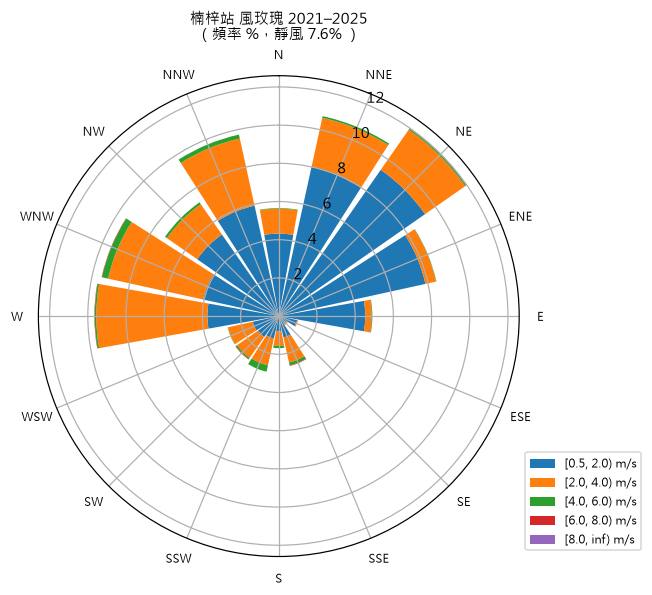

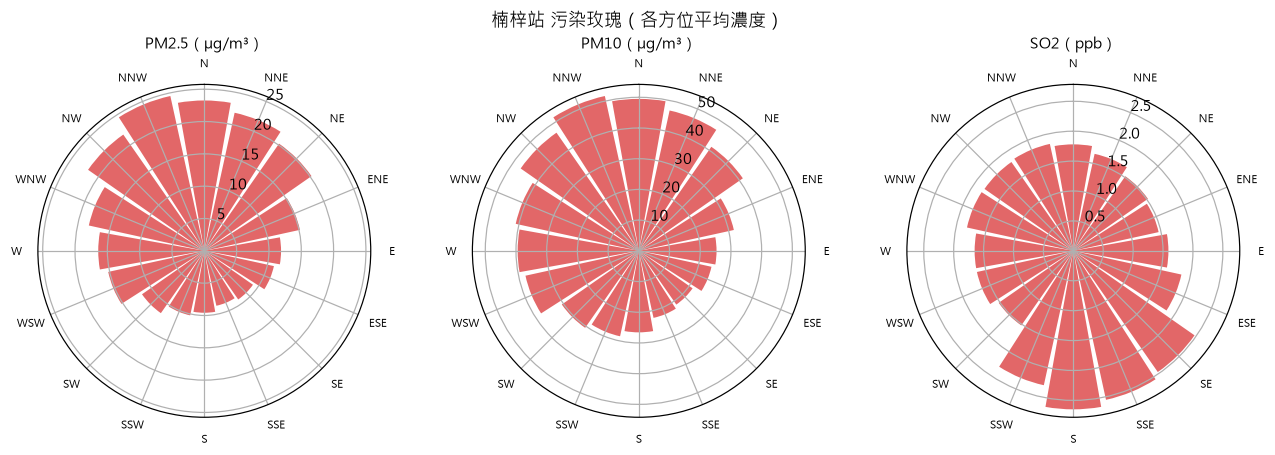

In [71]:
SECTOR_NAMES = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
SPEED_BINS = [CALM_WS, 2, 4, 6, 8, np.inf]


def wind_table(df: pd.DataFrame, site: str) -> pd.DataFrame:
    '''每小時的風向方位（0=N … 15=NNW）與是否靜風。'''
    w = _wide(df, site, [ITEM_WD, ITEM_WS]).dropna()
    sector = (((w[ITEM_WD] + 11.25) % 360) // 22.5).astype(int)
    return w.assign(sector=sector, calm=w[ITEM_WS] < CALM_WS)


def wind_rose(w: pd.DataFrame):
    '''回傳 (16 方位 × 風速級 的頻率百分比, 靜風百分比)。頻率的分母是全部有效小時（含靜風）。'''
    nc = w[~w["calm"]].copy()
    nc["spd"] = pd.cut(nc[ITEM_WS], SPEED_BINS, right=False)
    freq = (nc.groupby(["sector", "spd"], observed=False).size().unstack("spd")
              .reindex(range(16), fill_value=0) / len(w) * 100)
    freq.index = SECTOR_NAMES
    return freq.round(2), round(w["calm"].mean() * 100, 2)


def pollution_rose(df: pd.DataFrame, site: str, w: pd.DataFrame, items) -> pd.DataFrame:
    conc = _wide(df, site, items)
    j = w[["sector", "calm"]].join(conc, how="inner")
    j = j[~j["calm"]]
    out = j.groupby("sector")[list(items)].mean().reindex(range(16))
    out.index = SECTOR_NAMES
    return out.round(2)


def plot_wind_rose(freq: pd.DataFrame, calm_pct: float, title: str, fname: str):
    theta = np.deg2rad(np.arange(16) * 22.5)
    width = np.deg2rad(22.5) * 0.9
    fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    bottom = np.zeros(16)
    for col in freq.columns:
        ax.bar(theta, freq[col].values, width=width, bottom=bottom, label=f"{col} m/s")
        bottom += freq[col].values
    ax.set_xticks(theta); ax.set_xticklabels(SECTOR_NAMES, fontsize=8)
    ax.set_title(f"{title}\n（頻率 %，靜風 {calm_pct:.1f}% ）", fontsize=10)
    ax.legend(loc="lower left", bbox_to_anchor=(1.0, 0.0), fontsize=8)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def plot_pollution_rose(prose: pd.DataFrame, title: str, fname: str):
    theta = np.deg2rad(np.arange(16) * 22.5)
    fig, axes = plt.subplots(1, len(prose.columns), figsize=(4 * len(prose.columns), 4),
                             subplot_kw={"projection": "polar"})
    for ax, item in zip(np.atleast_1d(axes), prose.columns):
        ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
        ax.bar(theta, prose[item].values, width=np.deg2rad(22.5) * 0.9, color="tab:red", alpha=0.7)
        ax.set_xticks(theta); ax.set_xticklabels(SECTOR_NAMES, fontsize=7)
        ax.set_title(f"{item}（{UNITS.get(item, '')}）", fontsize=10)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


ITEMS_ROSE = ["PM2.5", "PM10", "SO2"]
wt = wind_table(hourly, SITE)
freq, calm_pct = wind_rose(wt)
prose = pollution_rose(hourly, SITE, wt, ITEMS_ROSE)
# 風玫瑰與污染玫瑰的數值表只在 notebook 內顯示，輸出以圖為準；摘要數字併入第 6.5 節設計輸入表
print(f"有效風資料小時數 {len(wt)}，靜風 {calm_pct}%")
display(freq.assign(total=freq.sum(axis=1).round(2)))
display(prose)
plot_wind_rose(freq, calm_pct, f"{SITE}站 風玫瑰 {YEARS[0]}–{YEARS[-1]}", f"{PREFIX}_wind_rose_{SITE_EN}.png")
plot_pollution_rose(prose, f"{SITE}站 污染玫瑰（各方位平均濃度）", f"{PREFIX}_pollution_rose_{SITE_EN}.png")

## 6. 設計輸入表

紀錄所需設計值。6.1～6.4 各自對應一個設計決策並在 notebook 內顯示，6.5 把其中設計組要的數字彙整成唯一一個出檔 `01_design_inputs_Nanzih.csv`；假設都寫在這裡：

**6.1 外氣 PM 濃度 Cout（#1）**：列出五年合併小時值的平均、P50、P95、P99、最大值，五個統計量並列，設計值要取哪一個由設計組決定（高百分位代表濾網要撐過的高濃度時段，平均代表長期負荷）。本節之後的示例換算以 `REF_PCT`（P95）當參考值，只是為了示範，不代表已選定。講義 CR p43 的潔淨度公式要的是「每立方公尺 ≥ 0.5 µm 的粒子數」，測站只有質量濃度，兩者之間沒有可靠的換算依據（要先知道粒徑分布與粒子密度，而這兩項測站都沒有量）。
- 本表只給質量濃度；公式需要的粒子數或由合理假設推測，或問 TSMC 人員囉!!

**潔淨度公式**（講義 CR p43、p44，兩種氣流模型）。先建立畫面：外氣經 MAU 的三段濾網進入循環系統，與回風混合後再經 FFU 的 ULPA 送進潔淨室；室內另有人員與設備自己產生的粒子。公式就是把這兩條來源加起來，再乘以最後一道 ULPA 的穿透率。

單向流（unidirectional，CR p43，ULPA 在整個循環風路的末端，室內發塵也要經過它）：

$$C = \left[\frac{\chi S}{Q} + (1-\chi)(1-\eta_{p1})(1-\eta_{p2})(1-\eta_{p3})\,C_{out}\right](1-\eta_f)$$

亂流混合（turbulent mixing，CR p44，室內發塵直接混入室內空氣，只有外氣經過 FFU）：

$$C = \frac{S}{Q} + (1-\chi)(1-\eta_{p1})(1-\eta_{p2})(1-\eta_{p3})(1-\eta_f)\,C_{out}$$

| 符號 | 意義 | 單位 | 來源 |
|---|---|---|---|
| $C$ | 潔淨室內的粒子濃度（≥ 0.5 µm），對照 ISO 14644-1 等級 | 個/m³ | 計算結果 |
| $C_{out}$ | 外氣的粒子濃度（≥ 0.5 µm） | 個/m³ | **本 notebook 只能給質量濃度**，顆數需另行取得 |
| $S$ | 室內粒子產生率（人員、設備、製程） | 個/s | 設計組，依人數與設備估 |
| $Q$ | 總送風量 | m³/s | 設計組，由 FFU 覆蓋率與換氣次數決定 |
| $\chi$ | 回風比例（循環風佔送風的比例）；$1-\chi$ 就是外氣比例 | 無因次 | 設計組，半導體廠外氣比例通常只有百分之幾 |
| $\eta_{p1}$ | MAU 第一段預濾（pre filter）的捕集效率 | 無因次 | 6.2 節選定的 ISO 16890 等級 |
| $\eta_{p2}$ | MAU 第二段中效（after filter）的捕集效率 | 無因次 | 同上 |
| $\eta_{p3}$ | MAU 第三段 HEPA 的捕集效率 | 無因次 | 依 EN 1822 等級（H13 ≥ 99.95％、H14 ≥ 99.995％） |
| $\eta_f$ | FFU 內 ULPA 的捕集效率 | 無因次 | 依 EN 1822 等級（U15 ≥ 99.9995％ 起） |

讀法：每過一段濾網，穿透的比例是 $(1-\eta)$，串聯就相乘；外氣只佔送風的 $(1-\chi)$，所以外氣項前面要再乘這個比例。把典型數字代進去可以看出外氣項的量級：都市外氣 ≥ 0.5 µm 約每立方公尺 10⁷～10⁸ 個（文獻常見範圍，非楠梓實測），乘上 H13 的穿透 5×10⁻⁴ 與 U15 的穿透 5×10⁻⁶，剩不到 1 個/m³，遠低於 ISO 5 的 3,520 個/m³。因此潔淨室等級實際上由 $S/Q$（室內發塵與風量）決定，外氣項用數量級估計即可，這也是本表不強求顆數的原因；外氣顆數真正影響的是 HEPA 與 ULPA 的壽命。

**6.2 ISO 16890 濾網等級（#2）**：ISO 16890 以 ePM1、ePM2.5、ePM10 的質量捕集效率分級（50％～95％，每 5％ 一級）。本表只提供一個換算關係：給定某個 MAU 出口目標濃度，所需的整體捕集效率 = 1 − 目標濃度 ÷ Cout，再對應到最接近的等級。表中的外氣值用 P95 當參考、目標濃度也只是示例，兩者都不是設計決定；設計值取哪個百分位、目標濃度要訂多少、MAU 分幾段、各段用什麼等級、是否需要 EPA／HEPA 級，都由設計組依系統配置決定。這張示例表只顯示、不出檔。
* 須詢問通過 MAU 後的目標濃度

**6.3 AMC 氣體濃度（#3）**：SO2、NO2、O3 的平均、P95、P99，從 ppb 換成 µg/m³（25℃、1 atm：µg/m³ = ppb × 分子量 ÷ 24.45），並換成 ISO 14644-8 的表示法：ISO-AMC class N 代表濃度 10^N g/m³，例如 10 µg/m³ = 10⁻⁵ g/m³ 即 class −5。NMHC 是 ppmC（以碳計的總量），無法換成單一物種的 µg/m³，保留原單位。NH3、H2S 測站沒有，表中留空並註明。
* 詢問方法，或以保守設計處理

**6.4 風向（#3、#4）**：盛行方位（頻率前三）、海風方位（楠梓在海岸東側，取 SW～WNW 四個方位）的總頻率與白天（10～16 時）頻率、污染玫瑰中 PM2.5 與 SO2 最高的方位。給 MAU 進氣口方位與是否需要鹽霧濾網的判斷用。

**6.5 設計輸入表**：把 6.1 的 PM 統計、6.3 的 AMC 濃度與等級、6.4 的風向摘要疊成一張長格式表，欄位固定為 `category、item、metric、value、unit、note`。用長格式而不是寬表，是因為三類的統計量名稱不同（PM 有 P95，風向是文字描述），寬表會留一堆空格；長格式每列自帶單位與備註，設計組篩 `category` 就能取用，報告引用也只對這一個檔。

In [ ]:
# ---- 6.1 外氣 PM 濃度統計（候選設計值並列，取哪一個由設計組決定）
def pm_stats(df: pd.DataFrame, site: str) -> pd.DataFrame:
    rows = []
    for item in ITEMS_PM:
        s = df[(df["site"] == site) & (df["item"] == item)]["value"].dropna()
        rows.append({"item": item, "unit": UNITS[item], "n_valid": len(s), "mean": s.mean(), "p50": s.median(),
                     "p95": s.quantile(0.95), "p99": s.quantile(0.99), "max": s.max()})
    return pd.DataFrame(rows).set_index("item").round(1)


pm_tbl = pm_stats(hourly, SITE)
pm25_ref, pm10_ref = pm_tbl.loc["PM2.5", f"p{REF_PCT}"], pm_tbl.loc["PM10", f"p{REF_PCT}"]
print(f"6.1 外氣 PM 濃度統計（{YEARS[0]}–{YEARS[-1]} 合併小時值）；下方示例換算以 P{REF_PCT} 為參考值")
display(pm_tbl)

# ---- 6.2 ISO 16890（示例換算，只顯示不出檔）
ISO16890_CLASSES = list(range(50, 100, 5))
TARGETS = {"PM2.5": [10, 5, 2, 1], "PM10": [20, 10, 5, 2]}   # MAU 出口目標濃度示例值（µg/m³），實際目標由設計組決定


def iso16890_required(cout: float, item: str) -> pd.DataFrame:
    group = {"PM2.5": "ePM2.5", "PM10": "ePM10"}[item]
    rows = []
    for tgt in TARGETS[item]:
        eff = 1 - tgt / cout
        cls = next((c for c in ISO16890_CLASSES if c >= eff * 100), None)
        rows.append({"item": item, f"cout_p{REF_PCT}": cout, "target_outlet": tgt, "required_eff_%": round(eff * 100, 1),
                     "iso16890_class": f"{group} {cls}%" if cls is not None else "超出 ISO 16890 範圍（>95%）"})
    return pd.DataFrame(rows)


iso_tbl = pd.concat([iso16890_required(pm25_ref, "PM2.5"), iso16890_required(pm10_ref, "PM10")], ignore_index=True)
print(f"6.2 ISO 16890 所需整體效率與等級（示例，以 P{REF_PCT} 為外氣參考值）")
display(iso_tbl)

# ---- 6.3 AMC
def amc_stats(df: pd.DataFrame, site: str) -> pd.DataFrame:
    rows = []
    for item in ["SO2", "NO2", "O3", "NMHC"]:
        s = df[(df["site"] == site) & (df["item"] == item)]["value"].dropna()
        r = {"item": item, "unit_raw": UNITS[item], "mean": s.mean(), "p95": s.quantile(0.95), "p99": s.quantile(0.99)}
        if item in MW:
            f = MW[item] / 24.45
            r.update({"mean_ug_m3": s.mean() * f, "p95_ug_m3": s.quantile(0.95) * f,
                      "ISO14644-8_class_mean": np.log10(s.mean() * f * 1e-6),
                      "ISO14644-8_class_p95": np.log10(s.quantile(0.95) * f * 1e-6)})
        rows.append(r)
    for item in ["NH3", "H2S"]:
        rows.append({"item": item, "unit_raw": "測站無此測項，無資料"})
    return pd.DataFrame(rows).set_index("item").round(2)


amc_tbl = amc_stats(hourly, SITE)
print("6.3 AMC 相關氣體濃度（ISO 14644-8 class N 表示 10^N g/m³）")
display(amc_tbl)

# ---- 6.4 風向
SEA_BREEZE_SECTORS = ["SW", "WSW", "W", "WNW"]   # 楠梓在海岸東側，海風來自西～西南


def wind_summary(wt: pd.DataFrame, freq: pd.DataFrame, prose: pd.DataFrame) -> pd.DataFrame:
    total = freq.sum(axis=1)
    top3 = total.sort_values(ascending=False).head(3)
    nc = wt[~wt["calm"]]
    day = nc[(nc.index.hour >= 10) & (nc.index.hour <= 16)]
    sea_idx = [SECTOR_NAMES.index(s) for s in SEA_BREEZE_SECTORS]
    rows = [
        {"指標": "盛行方位（頻率前三）", "值": "、".join(f"{k} {v:.1f}%" for k, v in top3.items())},
        {"指標": "靜風比例", "值": f"{wt['calm'].mean() * 100:.1f}%"},
        {"指標": f"海風方位 {'/'.join(SEA_BREEZE_SECTORS)} 全日頻率", "值": f"{nc['sector'].isin(sea_idx).mean() * 100:.1f}%（分母：非靜風小時）"},
        {"指標": "海風方位 白天 10–16 時頻率", "值": f"{day['sector'].isin(sea_idx).mean() * 100:.1f}%"},
    ]
    for item in prose.columns:
        top = prose[item].sort_values(ascending=False).head(3)
        rows.append({"指標": f"{item} 濃度最高的方位（前三）", "值": "、".join(f"{k} {v:.1f}" for k, v in top.items()) + f" {UNITS.get(item, '')}"})
    return pd.DataFrame(rows).set_index("指標")


wind_tbl = wind_summary(wt, freq, prose)
print("6.4 風向摘要")
display(wind_tbl)

# ---- 6.5 彙整成單一設計輸入表（長格式：category, item, metric, value, unit, note）
rows = []
for item, r in pm_tbl.iterrows():
    for metric in ["mean", "p50", "p95", "p99", "max"]:
        rows.append(("PM", item, metric, r[metric], r["unit"], f"{YEARS[0]}–{YEARS[-1]} 合併小時值，n={int(r['n_valid'])}；設計值取哪個統計量由設計組決定"))
for item, r in amc_tbl.iterrows():
    if item in ("NH3", "H2S"):
        rows.append(("AMC", item, "", np.nan, "", "測站無此測項，無資料"))
        continue
    for metric in ["mean", "p95", "p99"]:
        rows.append(("AMC", item, metric, r[metric], r["unit_raw"], f"{YEARS[0]}–{YEARS[-1]} 合併小時值"))
    if item in MW:
        for metric in ["mean_ug_m3", "p95_ug_m3"]:
            rows.append(("AMC", item, metric, r[metric], "µg/m³", "25℃、1 atm 由 ppb 換算"))
        for metric in ["ISO14644-8_class_mean", "ISO14644-8_class_p95"]:
            rows.append(("AMC", item, metric, r[metric], "class", "ISO 14644-8：log10(g/m³)"))
for idx, r in wind_tbl.iterrows():
    rows.append(("WIND", idx, "", r["值"], "", f"{YEARS[0]}–{YEARS[-1]} 小時風資料，靜風 < {CALM_WS} m/s 不計方位"))
design_inputs = pd.DataFrame(rows, columns=["category", "item", "metric", "value", "unit", "note"])
design_inputs.to_csv(PROC_DIR / f"{PREFIX}_design_inputs_{SITE_EN}.csv", index=False)
print("6.5 設計輸入表（長格式，唯一要交給設計組的檔）")
display(design_inputs)

## 7. 小結
要特別注意的事：

- **PM 與 ISO 16890 的數字可以直接用**；潔淨度公式要的 ≥ 0.5 µm 粒子數測站沒有量測。
- **AMC 只有酸性（SO2）、氧化性（NO2、O3）、總有機（NMHC）四項有數據**，NH3 與 H2S 沒有測站資料。


【楠梓站 2021–2025 外氣品質摘要】
- 設計用外氣濃度（P95）：PM2.5 41.0 µg/m³、PM10 81.0 µg/m³；五年平均 PM2.5 18.1、PM10 39.6 µg/m³。
- 若以 PM2.5 出口目標 1 µg/m³ 計，MAU 整體所需效率 97.6%，對應 超出 ISO 16890（>95%），需 EPA/HEPA（EN 1822/ISO 29463）。
- AMC：SO2 平均 4.49 µg/m³（ISO-AMC class -5.3）、NO2 24.41 µg/m³、O3 54.76 µg/m³；NH3、H2S 無資料。
- 風向：NE 12.0%、NNE 10.7%、NNW 9.7%；7.6% 靜風；海風方位白天頻率 59.5%。
- PM2.5 濃度最高來向：NNW 24.5、N 23.3、NW 21.9 µg/m³；SO2：S 2.6、SSE 2.5、SE 2.5 ppb。
- 有效率低於 75% 的測項／年份：無。